# Retreino dos Três Baselines no Pipeline Congelado

**Objetivo:** retreinar `DummyClassifier`, **Persistência temporal** e `GaussianNB` no **mesmo split da Sprint 2/3** (treino 2015–2022, teste 2023–2024), agora com as features da Sprint 4 e o `ColumnTransformer` congelado.

**Entrada:** `data/processed/dados_modelo.csv` (saída do notebook 08) e a lista final de 4 atributos selecionada **só no treino**.  
**Saída:** modelos retreinados + Recall, Precisão, F1 e matriz de confusão **por classe**, em **contagens absolutas**.

**Regras seguidas aqui**
- `fit` somente no treino (2015–2022); o teste só é usado para `predict` e métricas.
- Sem SMOTE/oversampling e **sem ajuste de limiar** (isso é Sprint 5).
- Métricas da Sprint 3 **não são coladas**: o S3 é reproduzido neste notebook, com o mesmo código, apenas para calcular o delta.
- Métrica que não pode ser calculada (ex.: recall sem nenhum evento real) aparece como **`n/d`**, e não como 0 ou 1.

In [4]:
%pip install -r ../requirements.txt

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: C:\Users\josea\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [5]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix

sns.set_theme(style='whitegrid')

# ---------------- Configuração do experimento ----------------
RANDOM_STATE = 42          # Dummy(most_frequent) e GaussianNB são determinísticos; fixado só por documentação
ANO_CORTE_TREINO = 2022    # treino: ano <= 2022 | teste: ano >= 2023 (mesmo corte da Sprint 2/3)
TARGET = 'quebra_safra'    # 1 = Quebra (rendimento < 3.400 kg/ha), 0 = Normal
CLASSES = [0, 1]
ORDEM_MODELOS = ['DummyClassifier', 'Persistência', 'GaussianNB']

# ---------------- Atributos CONGELADOS (Sprint 4, notebook 08) ----------------
FEATURES_S4 = [
    'deficit_hidrico_solo',      # dias Jan-Fev com GWETROOT < 0,70
    'dias_pico_calor',           # dias Jan-Fev com T2M_MAX >= 35 °C
    'amplitude_termica',         # herdada da Sprint 2
    'precipitacao_enchimento',   # chuva acumulada Jan-Fev (mm)
]

# Atributos da Sprint 3 (usados SÓ para reproduzir o baseline antigo e medir o delta)
FEATURES_S3 = [
    'PRECTOTCORR', 'T2M', 'T2M_MAX', 'T2M_MIN', 'RH2M', 'GWETROOT',
    'amplitude_termica', 'precipitacao_por_temperatura', 'GWET_x_PREC',
]

# Colunas que jamais podem virar feature (identificador temporal, alvo e variáveis pós-colheita)
COLUNAS_PROIBIDAS = {'ano', TARGET, 'rendimento_kg_ha', 'quantidade_produzida_t',
                     'area_colhida_ha', 'area_plantada_ha'}
assert not COLUNAS_PROIBIDAS & set(FEATURES_S4), 'Vazamento: coluna proibida em FEATURES_S4'
assert not COLUNAS_PROIBIDAS & set(FEATURES_S3), 'Vazamento: coluna proibida em FEATURES_S3'
print('Configuração carregada. Features S4:', FEATURES_S4)

Configuração carregada. Features S4: ['deficit_hidrico_solo', 'dias_pico_calor', 'amplitude_termica', 'precipitacao_enchimento']


## 1. Dados e split temporal (mesmo corte da Sprint 2/3)

Treino = safras antigas, teste = safras recentes, **sem embaralhar**. O corte é o mesmo de `02_limpeza_split_temporal.ipynb`, `06_modelagem_baselines.ipynb` e `07_dummyclassifier_gaussiannb_pipeline.ipynb`.

In [6]:
df = pd.read_csv('../data/processed/dados_modelo.csv').sort_values('ano').reset_index(drop=True)

# ---------- Verificações de integridade ----------
necessarias = set(FEATURES_S3) | set(FEATURES_S4) | {TARGET, 'ano'}
faltando = sorted(necessarias - set(df.columns))
assert not faltando, f'Colunas ausentes em dados_modelo.csv (rode o notebook 08): {faltando}'
assert df['ano'].is_unique, 'Há safras duplicadas'
assert (df['ano'].diff().dropna() == 1).all(), 'Série anual não é consecutiva (a persistência depende disso)'
assert df[sorted(necessarias)].isna().sum().sum() == 0, 'Há NaN nas colunas usadas'

# ---------- Split temporal ----------
train_mask = df['ano'] <= ANO_CORTE_TREINO
test_mask = ~train_mask

df_train = df[train_mask].copy()
df_test = df[test_mask].copy()
assert df_train['ano'].max() < df_test['ano'].min(), 'Treino e teste se sobrepõem no tempo'

y_train, y_test = df_train[TARGET], df_test[TARGET]

# Rótulo observado por safra (a persistência usa o rótulo da safra t-1, já conhecido na decisão de t)
ROTULO_POR_ANO = df.set_index('ano')[TARGET]

print(f"Período total: {df['ano'].min()}–{df['ano'].max()}  (N = {len(df)} safras)")
print(f"Treino: {df_train['ano'].min()}–{df_train['ano'].max()}  (N = {len(df_train)})")
print(f"Teste : {df_test['ano'].min()}–{df_test['ano'].max()}  (N = {len(df_test)})")
print(f"\nQuebras no treino: {int(y_train.sum())} de {len(y_train)}  -> {y_train.value_counts().to_dict()}")
print(f"Quebras no teste : {int(y_test.sum())} de {len(y_test)}  -> {y_test.value_counts().to_dict()}")

if y_test.sum() == 0:
    print('\nATENÇÃO: o teste não tem nenhum evento de Quebra. Recall/F1 da classe 1 são indefinidos (n/d)')
    print('e a acurácia alta NÃO indica qualidade preditiva. Veja o backtest da seção 6 como diagnóstico complementar.')

display(df_train[['ano', TARGET]].set_index('ano').T)

Período total: 2015–2024  (N = 10 safras)
Treino: 2015–2022  (N = 8)
Teste : 2023–2024  (N = 2)

Quebras no treino: 3 de 8  -> {0: 5, 1: 3}
Quebras no teste : 0 de 2  -> {0: 2}

ATENÇÃO: o teste não tem nenhum evento de Quebra. Recall/F1 da classe 1 são indefinidos (n/d)
e a acurácia alta NÃO indica qualidade preditiva. Veja o backtest da seção 6 como diagnóstico complementar.


ano,2015,2016,2017,2018,2019,2020,2021,2022
quebra_safra,1,1,0,0,0,0,1,0


## 2. Pipeline congelado

Um único `Pipeline` por modelo: `ColumnTransformer` **+** classificador no mesmo objeto, com `fit` apenas no treino.

| Decisão | Justificativa |
|---|---|
| Lista de colunas = `FEATURES_S4` (4 atributos) | Seleção parcimoniosa feita só no treino (notebook 08), compatível com N de treino = 8 |
| `StandardScaler` | Os 4 atributos têm unidades diferentes (dias, °C, mm). Mantido por consistência com a Sprint 3 e para a Sprint 5 poder plugar modelos lineares sem mexer no transformer. Observação: `GaussianNB` e `DummyClassifier` praticamente não dependem da escala |
| Sem imputer | Notebook 03 confirmou 0 NA; a leitura acima reforça com `assert` |
| Sem encoder | Nenhuma variável categórica: município é único (Sorriso-MT) e `ano` não entra como feature |
| `remainder='drop'` | Qualquer coluna fora da lista (inclusive `ano` e o alvo) é descartada, o que evita vazamento acidental |

A **Persistência** não aprende nada das features: a previsão da safra *t* é o rótulo observado em *t−1*. Portanto o resultado dela **não muda** entre S3 e S4 (delta = 0 por construção).

In [7]:
def construir_preprocessor(features):
    # ColumnTransformer congelado: padroniza as features listadas e descarta o resto.
    return ColumnTransformer(
        transformers=[('escala_climatica', StandardScaler(), list(features))],
        remainder='drop',
    )


def criar_pipeline(modelo, features):
    # Pipeline = pré-processamento + classificador (um objeto só; fit só no treino).
    return Pipeline([
        ('preprocessor', construir_preprocessor(features)),
        ('model', modelo),
    ])


def prever_baselines(features, df_tr, df_te):
    # Treina Dummy e GaussianNB SOMENTE em df_tr e prevê df_te; persistência = rótulo de t-1.
    preds, pipes = {}, {}
    modelos = {
        'DummyClassifier': DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE),
        'GaussianNB': GaussianNB(),
    }
    for nome, modelo in modelos.items():
        pipe = criar_pipeline(modelo, features)
        pipe.fit(df_tr[features], df_tr[TARGET])
        preds[nome] = pipe.predict(df_te[features])
        pipes[nome] = pipe

    persistencia = df_te['ano'].map(lambda a: ROTULO_POR_ANO.get(a - 1, np.nan))
    assert persistencia.notna().all(), 'Persistência sem rótulo da safra anterior'
    preds['Persistência'] = persistencia.astype(int).to_numpy()

    preds = {k: preds[k] for k in ORDEM_MODELOS}
    return preds, pipes


def _prf(tp, fp, fn):
    # Precisão, recall e F1 de UMA classe; devolve NaN quando a conta é indefinida (denominador 0).
    precisao = tp / (tp + fp) if (tp + fp) > 0 else np.nan
    recall = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    f1 = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else np.nan
    return precisao, recall, f1


def metricas_por_classe(nome, y_true, y_pred):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=CLASSES).ravel()
    p1, r1, f1_1 = _prf(tp, fp, fn)   # classe 1 = Quebra (positiva)
    p0, r0, f1_0 = _prf(tn, fn, fp)   # classe 0 = Normal
    return {
        'modelo': nome, 'N': len(y_true),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
        'suporte_Normal': int(tn + fp), 'suporte_Quebra': int(fn + tp),
        'precisao_Normal': p0, 'recall_Normal': r0, 'f1_Normal': f1_0,
        'precisao_Quebra': p1, 'recall_Quebra': r1, 'f1_Quebra': f1_1,
        'acuracia': (tn + tp) / len(y_true),
    }


def tabela_metricas(preds, y_true):
    return pd.DataFrame([metricas_por_classe(n, y_true, p) for n, p in preds.items()])


def formatar(df_, casas=2):
    # Mostra NaN como 'n/d' (indefinido) em vez de esconder como 0.
    def _f(v):
        if isinstance(v, (float, np.floating)):
            return 'n/d' if np.isnan(v) else f'{v:.{casas}f}'
        return v
    return df_.astype(object).apply(lambda col: col.map(_f))


def tabela_lift(m_s3, m_s4):
    # Delta S3 -> S4 para a classe positiva (Quebra).
    t = pd.DataFrame({
        'Modelo': m_s4['modelo'],
        'Recall S3': m_s3['recall_Quebra'], 'Recall S4': m_s4['recall_Quebra'],
        'F1 S3': m_s3['f1_Quebra'], 'F1 S4': m_s4['f1_Quebra'],
        'FN S3': m_s3['FN'], 'FN S4': m_s4['FN'],
        'Eventos reais': m_s4['suporte_Quebra'],
    })
    t['Delta recall'] = t['Recall S4'] - t['Recall S3']
    return t

print('Funções do pipeline congelado definidas.')

Funções do pipeline congelado definidas.


## 3. Retreino dos três baselines (features S4)

`fit` somente em 2015–2022. O teste (2023–2024) só entra no `predict`.

In [8]:
preds_s4, pipes_s4 = prever_baselines(FEATURES_S4, df_train, df_test)

dummy = pipes_s4['DummyClassifier'].named_steps['model']
nb = pipes_s4['GaussianNB'].named_steps['model']
classe_dummy = dummy.classes_[np.argmax(dummy.class_prior_)]

print('Pipelines retreinados com fit apenas no treino (2015–2022).')
print(f'Features no ColumnTransformer: {FEATURES_S4}')
print(f"Dummy      -> prevê sempre a classe {classe_dummy} | priors do treino: {dict(zip(dummy.classes_.tolist(), dummy.class_prior_.round(3).tolist()))}")
print(f"GaussianNB -> priors do treino: {dict(zip(nb.classes_.tolist(), nb.class_prior_.round(3).tolist()))}")
print(f"Persistência -> rótulo da safra anterior (t-1)")

previsoes_teste = pd.DataFrame({'ano': df_test['ano'].to_numpy(), 'real': y_test.to_numpy()})
for nome, p in preds_s4.items():
    previsoes_teste[nome] = p
print('\nPrevisões por safra no teste (0 = Normal, 1 = Quebra):')
display(previsoes_teste)

Pipelines retreinados com fit apenas no treino (2015–2022).
Features no ColumnTransformer: ['deficit_hidrico_solo', 'dias_pico_calor', 'amplitude_termica', 'precipitacao_enchimento']
Dummy      -> prevê sempre a classe 0 | priors do treino: {0: 0.625, 1: 0.375}
GaussianNB -> priors do treino: {0: 0.625, 1: 0.375}
Persistência -> rótulo da safra anterior (t-1)

Previsões por safra no teste (0 = Normal, 1 = Quebra):


,ano,real,DummyClassifier,Persistência,GaussianNB
0,2023,0,0,0,0
1,2024,0,0,0,0


## 4. Métricas por classe no teste (2023–2024) — contagens absolutas

`n/d` = métrica indefinida porque não há exemplos para calculá-la (ex.: recall da classe Quebra quando o teste não tem nenhuma Quebra).

In [9]:
metr_s4 = tabela_metricas(preds_s4, y_test)

print('Matriz de confusão e suportes — contagens absolutas (teste, features S4)')
display(metr_s4[['modelo', 'N', 'TN', 'FP', 'FN', 'TP', 'suporte_Normal', 'suporte_Quebra']])

print('\nPrecisão, Recall e F1 por classe (n/d = indefinido)')
display(formatar(metr_s4[['modelo', 'precisao_Normal', 'recall_Normal', 'f1_Normal',
                          'precisao_Quebra', 'recall_Quebra', 'f1_Quebra', 'acuracia']]))

print()
for _, l in metr_s4.iterrows():
    print(f"{l['modelo']}: {int(l['FN'])} FN em {int(l['suporte_Quebra'])} eventos reais de quebra | "
          f"{int(l['FP'])} FP em {int(l['suporte_Normal'])} safras normais")

Matriz de confusão e suportes — contagens absolutas (teste, features S4)


,modelo,N,TN,FP,FN,TP,suporte_Normal,suporte_Quebra
0,DummyClassifier,2,2,0,0,0,2,0
1,Persistência,2,2,0,0,0,2,0
2,GaussianNB,2,2,0,0,0,2,0



Precisão, Recall e F1 por classe (n/d = indefinido)


,modelo,precisao_Normal,recall_Normal,f1_Normal,precisao_Quebra,recall_Quebra,f1_Quebra,acuracia
0,DummyClassifier,1.00,1.00,1.00,n/d,n/d,n/d,1.00
1,Persistência,1.00,1.00,1.00,n/d,n/d,n/d,1.00
2,GaussianNB,1.00,1.00,1.00,n/d,n/d,n/d,1.00



DummyClassifier: 0 FN em 0 eventos reais de quebra | 0 FP em 2 safras normais
Persistência: 0 FN em 0 eventos reais de quebra | 0 FP em 2 safras normais
GaussianNB: 0 FN em 0 eventos reais de quebra | 0 FP em 2 safras normais


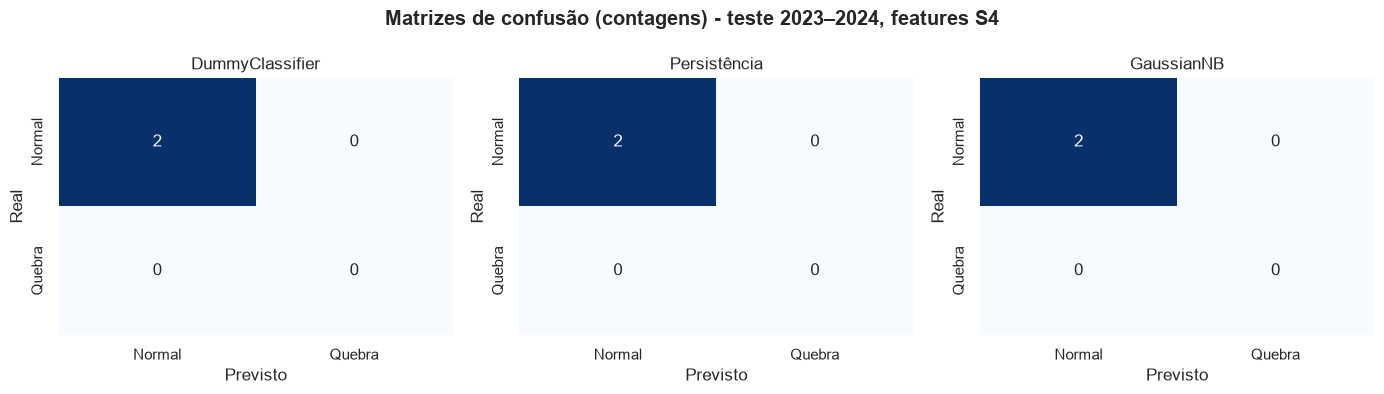

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
rotulos = ['Normal', 'Quebra']
for ax, (nome, pred) in zip(axes, preds_s4.items()):
    cm = confusion_matrix(y_test, pred, labels=CLASSES)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=rotulos, yticklabels=rotulos)
    ax.set_title(nome)
    ax.set_xlabel('Previsto')
    ax.set_ylabel('Real')
fig.suptitle('Matrizes de confusão (contagens) - teste 2023–2024, features S4', fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Reprodução do S3 no mesmo split e delta (classe positiva)

Os três baselines são retreinados com as **features da Sprint 3** usando o mesmo código e a mesma partição, apenas para ter um S3 comparável (nenhum número é colado de notebooks antigos).

In [11]:
preds_s3, pipes_s3 = prever_baselines(FEATURES_S3, df_train, df_test)
metr_s3 = tabela_metricas(preds_s3, y_test)

print('Teste oficial (2023–2024): delta S3 -> S4 na classe Quebra')
display(formatar(tabela_lift(metr_s3, metr_s4)))

if y_test.sum() == 0:
    print('\nSem eventos de Quebra no teste, recall/F1 e o delta são indefinidos. Isso NÃO significa "sem ganho":')
    print('significa que o teste oficial não consegue medir ganho. Use o backtest da seção 6 como evidência complementar.')

Teste oficial (2023–2024): delta S3 -> S4 na classe Quebra


,Modelo,Recall S3,Recall S4,F1 S3,F1 S4,FN S3,FN S4,Eventos reais,Delta recall
0,DummyClassifier,n/d,n/d,n/d,n/d,0,0,0,n/d
1,Persistência,n/d,n/d,n/d,n/d,0,0,0,n/d
2,GaussianNB,n/d,n/d,n/d,n/d,0,0,0,n/d



Sem eventos de Quebra no teste, recall/F1 e o delta são indefinidos. Isso NÃO significa "sem ganho":
significa que o teste oficial não consegue medir ganho. Use o backtest da seção 6 como evidência complementar.


## 6. Diagnóstico complementar: backtest temporal dentro do treino

Como o teste oficial pode não conter nenhuma Quebra, este bloco dá alguma evidência sobre a classe positiva **sem tocar no teste**: janela expansiva dentro de 2015–2022. Para cada safra-alvo (2019 a 2022), treina-se apenas com safras anteriores a ela.

**Limitações importantes (leia antes de usar os números):**
- São só **4 safras avaliadas**; qualquer métrica aqui é indicativa, não conclusiva.
- A seleção dos 4 atributos S4 (notebook 08) usou a correlação com o alvo em **todo o treino 2015–2022**, ou seja, já "viu" as safras avaliadas neste backtest. O desempenho S4 aqui é, portanto, **otimista** em relação ao S3. Use para checar coerência, não para afirmar ganho.
- Não substitui o teste oficial nem a validação temporal da Sprint 5.

In [12]:
ANO_INICIO_BACKTEST = 2019   # primeira dobra treina com 2015–2018 (4 safras)


def backtest_expansivo(features):
    registros = []
    for ano_alvo in range(ANO_INICIO_BACKTEST, ANO_CORTE_TREINO + 1):
        tr = df_train[df_train['ano'] < ano_alvo]
        va = df_train[df_train['ano'] == ano_alvo]
        preds, _ = prever_baselines(features, tr, va)
        for nome, p in preds.items():
            registros.append({'modelo': nome, 'ano': ano_alvo,
                              'y_true': int(va[TARGET].iloc[0]), 'y_pred': int(p[0])})
    return pd.DataFrame(registros)


def metricas_backtest(bt):
    linhas = [metricas_por_classe(n, g['y_true'], g['y_pred']) for n, g in bt.groupby('modelo')]
    return pd.DataFrame(linhas).set_index('modelo').loc[ORDEM_MODELOS].reset_index()


bt_s3 = backtest_expansivo(FEATURES_S3)
bt_s4 = backtest_expansivo(FEATURES_S4)

print('Previsões por safra no backtest (real vs. previsto), features S4:')
visao = bt_s4.pivot(index='ano', columns='modelo', values='y_pred')[ORDEM_MODELOS]
visao.insert(0, 'real', bt_s4.drop_duplicates('ano').set_index('ano')['y_true'])
display(visao)

bt_m3, bt_m4 = metricas_backtest(bt_s3), metricas_backtest(bt_s4)

print('\nBacktest 2019–2022 (agregado das 4 dobras) — contagens absolutas, features S4')
display(bt_m4[['modelo', 'N', 'TN', 'FP', 'FN', 'TP', 'suporte_Normal', 'suporte_Quebra']])

print('\nDelta S3 -> S4 no backtest (classe Quebra)  [S4 otimista: ver limitações acima]')
display(formatar(tabela_lift(bt_m3, bt_m4)))

Previsões por safra no backtest (real vs. previsto), features S4:


modelo,real,DummyClassifier,Persistência,GaussianNB
ano,,,,
2019,0,0,0,1
2020,0,0,0,0
2021,1,0,0,1
2022,0,0,1,0



Backtest 2019–2022 (agregado das 4 dobras) — contagens absolutas, features S4


,modelo,N,TN,FP,FN,TP,suporte_Normal,suporte_Quebra
0,DummyClassifier,4,3,0,1,0,3,1
1,Persistência,4,2,1,1,0,3,1
2,GaussianNB,4,2,1,0,1,3,1



Delta S3 -> S4 no backtest (classe Quebra)  [S4 otimista: ver limitações acima]


,Modelo,Recall S3,Recall S4,F1 S3,F1 S4,FN S3,FN S4,Eventos reais,Delta recall
0,DummyClassifier,0.00,0.00,0.00,0.00,1,1,1,0.00
1,Persistência,0.00,0.00,0.00,0.00,1,1,1,0.00
2,GaussianNB,0.00,1.00,0.00,0.67,1,0,1,1.00


## 7. Persistência dos artefatos

Os pipelines treinados (e o transformer já ajustado só no treino) ficam em `models/` para a Sprint 5 reutilizar **exatamente** o mesmo pré-processamento. O CSV de métricas alimenta a tabela de lift do diário.

In [13]:
os.makedirs('../models', exist_ok=True)

joblib.dump(pipes_s4['DummyClassifier'], '../models/s4_dummy_pipeline.joblib')
joblib.dump(pipes_s4['GaussianNB'], '../models/s4_gaussiannb_pipeline.joblib')
joblib.dump(pipes_s4['GaussianNB'].named_steps['preprocessor'], '../models/s4_preprocessor_congelado.joblib')
metr_s4.to_csv('../models/s4_metricas_baselines_teste.csv', index=False)
bt_m4.to_csv('../models/s4_metricas_baselines_backtest.csv', index=False)

print('Artefatos salvos em ../models/:')
for arq in sorted(os.listdir('../models')):
    if arq.startswith('s4_'):
        print(' -', arq)

Artefatos salvos em ../models/:
 - s4_dummy_pipeline.joblib
 - s4_gaussiannb_pipeline.joblib
 - s4_metricas_baselines_backtest.csv
 - s4_metricas_baselines_teste.csv
 - s4_preprocessor_congelado.joblib


## 8. Leitura crítica

In [14]:
n_pos_treino, n_pos_teste = int(y_train.sum()), int(y_test.sum())
print(f'Eventos de Quebra -> treino: {n_pos_treino} de {len(y_train)} | teste: {n_pos_teste} de {len(y_test)}\n')

if n_pos_teste == 0:
    print('O teste oficial não contém nenhuma Quebra:')
    print('- Recall e F1 da classe Quebra são indefinidos (n/d); só há FP possível, nunca FN.')
    print('- Os três baselines ficam indistinguíveis no teste; acurácia alta é efeito do desenho amostral.')
    print('- A decisão de negócio (custo do FN) não pode ser avaliada com este teste.')
else:
    print('Falsos negativos (previu Normal, houve Quebra), em contagem:')
    for _, l in metr_s4.iterrows():
        print(f"- {l['modelo']}: {int(l['FN'])} FN em {n_pos_teste} eventos; recall Quebra = "
              f"{'n/d' if pd.isna(l['recall_Quebra']) else format(l['recall_Quebra'], '.2f')}")

Eventos de Quebra -> treino: 3 de 8 | teste: 0 de 2

O teste oficial não contém nenhuma Quebra:
- Recall e F1 da classe Quebra são indefinidos (n/d); só há FP possível, nunca FN.
- Os três baselines ficam indistinguíveis no teste; acurácia alta é efeito do desenho amostral.
- A decisão de negócio (custo do FN) não pode ser avaliada com este teste.


**Como ler os resultados (preencher/ajustar após executar com os dados reais)**

1. **DummyClassifier** é piso de *acurácia* da classe majoritária; não é piso de recall da classe rara. Se o treino tem menos Quebras que Normais, ele prevê sempre Normal e **nunca** acerta uma Quebra.
2. **Persistência** não usa features: seu resultado é idêntico no S3 e no S4 (delta = 0 por construção). Serve de régua temporal: só ajuda se a Quebra tender a se repetir de uma safra para a seguinte.
3. **GaussianNB** estima média e variância por classe com poucas Quebras no treino (N muito pequeno), então as estimativas da classe positiva são instáveis. A hipótese de independência condicional continua sendo pedagógica: `deficit_hidrico_solo`, `dias_pico_calor` e `precipitacao_enchimento` ainda podem ser correlatas entre si (conferir o heatmap do notebook 08).
4. **Delta S3→S4**: só é interpretável se o teste (ou o backtest, com ressalvas) tiver eventos de Quebra. Se não houve ganho, registrar a hipótese e o que foi descartado, como pede a Sprint 4.
